Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7561 - loss: 0.9371 - val_accuracy: 0.8983 - val_loss: 0.3950
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8910 - loss: 0.3942 - val_accuracy: 0.9222 - val_loss: 0.2818
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9092 - loss: 0.3229 - val_accuracy: 0.9303 - val_loss: 0.2427
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9184 - loss: 0.2873 - val_accuracy: 0.9377 - val_loss: 0.2231
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9243 - loss: 0.2630 - val_accuracy: 0.9413 - val_loss: 0.2034
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9321 - loss: 0.2400
Test Loss: 0.2399914562702179
Test Accuracy: 93.2099997997284 %
Number of Epochs: 5


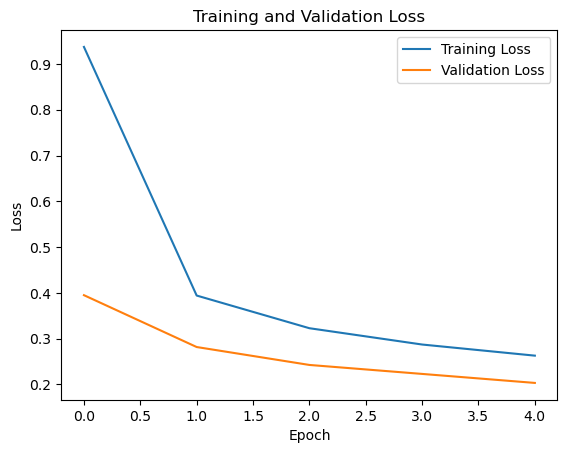

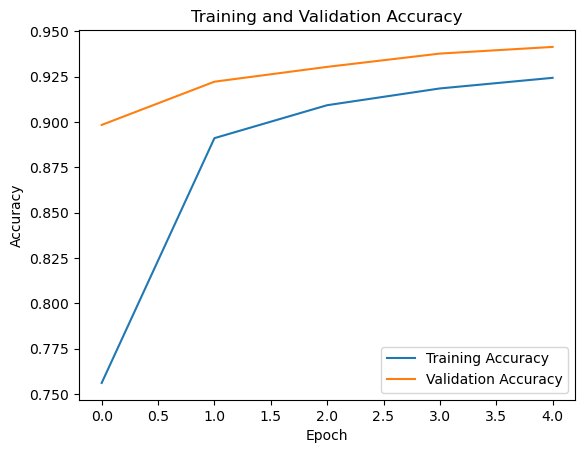

In [1]:
# Aim: Implement Feedforward Neural Network using Keras and TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
# a. Loading and preprocessing the data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
# Normalize pixel values between 0 and 1
x_train = x_train / 255.0
x_test = x_test / 255.0
# b. Defining the Feedforward Neural Network
model = models.Sequential([
layers.Input(shape=(28, 28)),
layers.Flatten(),
layers.Dense(128, activation='relu'),

layers.Dense(64, activation='relu'),
layers.Dense(10, activation='softmax')])
# Display model architecture
model.summary()
# c. Compile the model using SGD
model.compile(
optimizer='sgd',
loss='sparse_categorical_crossentropy',
metrics=['accuracy'])
# d. Training the model
history = model.fit(
x_train, y_train,
epochs=5,
batch_size=64,
validation_split=0.1)
# e. Evaluating the model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")
print("Number of Epochs:", len(history.epoch))
# f. Plotting training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()
# Plotting training accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()